
          LOAN RISK MANAGEMENT - MACHINE LEARNING

Input file : EMI_dataset_processed.csv
Target     : E13
Output     : loan_risk_results

[1/10] Loading dataset...

Dataset loaded successfully.
Rows    : 116058
Columns : 29

[2/10] Performing dataset audit...
Missing cells : 0
Duplicate rows: 0
Rows after duplicate removal: 116058

Creating dataset summary...
Dataset summary saved.

[3/10] Analysing target distribution...

Target distribution:
 Class  Count  Percentage
     0 115422   99.451998
     1    636    0.548002

Displaying Graph 1 - Target Distribution...


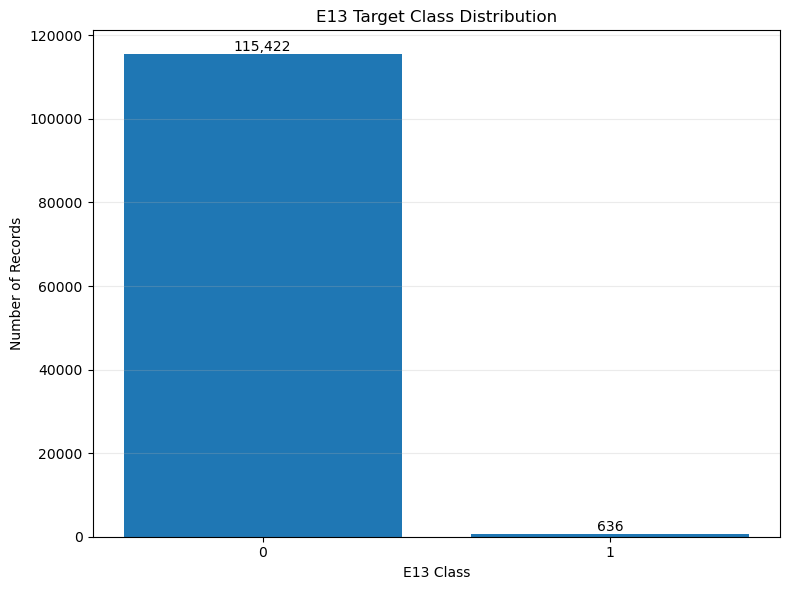


Identifier columns removed:
['candidate_id']

Categorical columns:
['country', 'organization', 'origination_date', 'first_payment_date', 'loan_purpose', 'insurance_type']

Numerical columns:
['interest_rate', 'unpaid_principal_bal', 'loan_term', 'loan_to_value', 'number_of_borrowers', 'debt_to_income_ratio', 'borrower_credit_score', 'insurance_percent', 'co-borrower_credit_score', 'E1', 'E2', 'E3', 'E4', 'E5', 'E6', 'E7', 'E8', 'E9', 'E10', 'E11', 'E12']

[4/10] Creating stratified train/test split...

Training records: 92846
Testing records : 23212

Training target distribution:
E13
0    92337
1      509
Name: count, dtype: int64

Testing target distribution:
E13
0    23085
1      127
Name: count, dtype: int64

[5/10] Preparing machine learning models...

XGBoost available.

[6/10] Training and evaluating models...

TRAINING: Logistic Regression

Metrics:
Accuracy       : 0.9293
Precision      : 0.0504
Recall         : 0.6693
F1             : 0.0938
Specificity    : 0.9307
ROC_AUC   

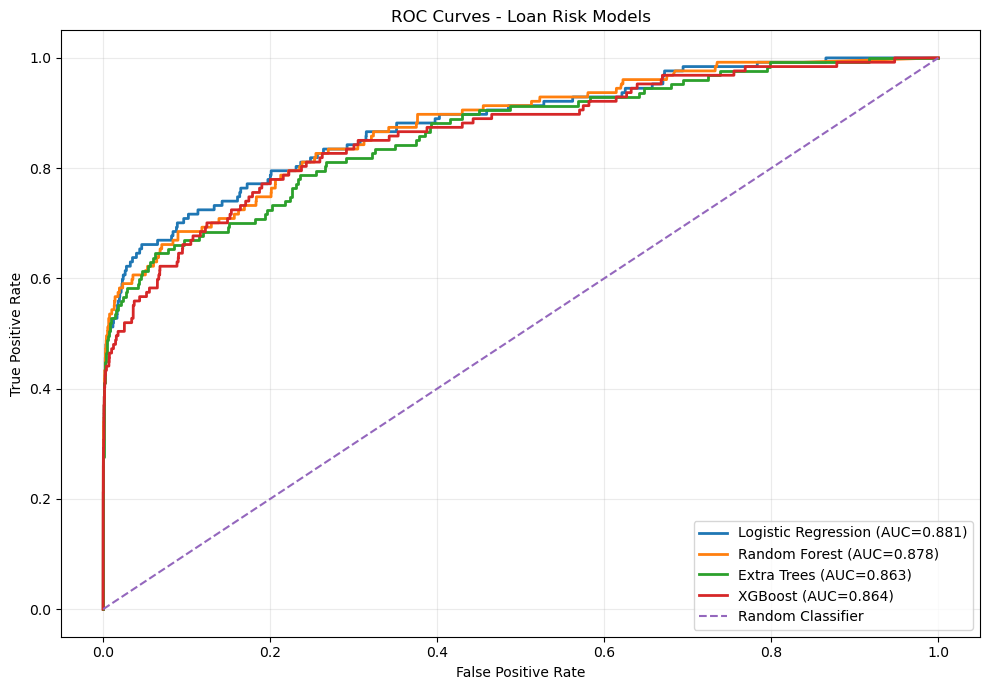


[8/10] Displaying Graph 3 - Precision-Recall Curves...


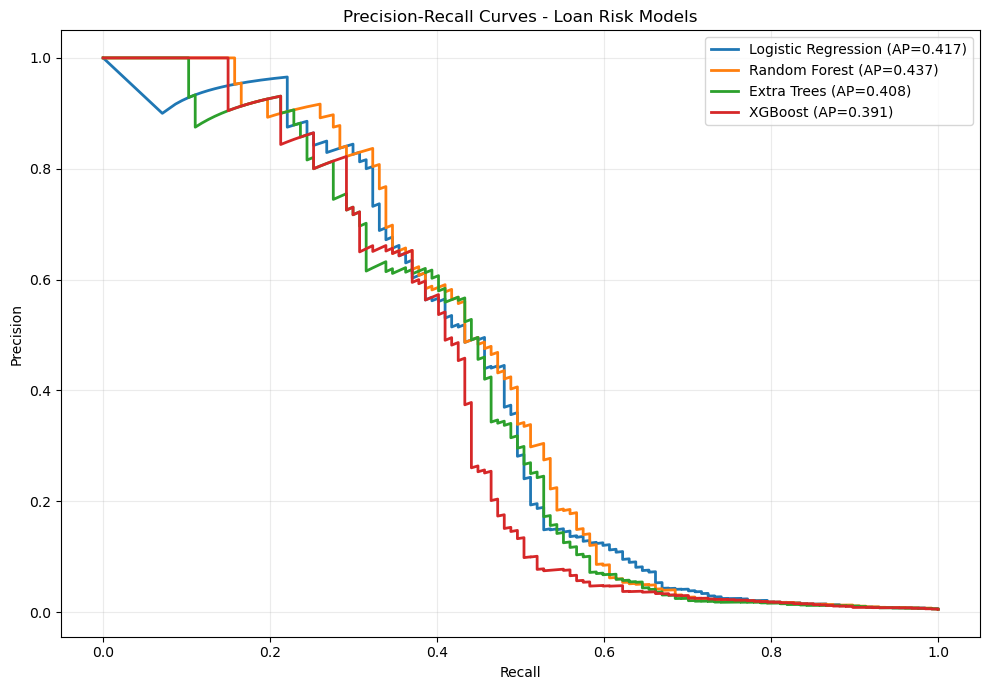


[9/10] Displaying Graph 4 - Model Performance Comparison...


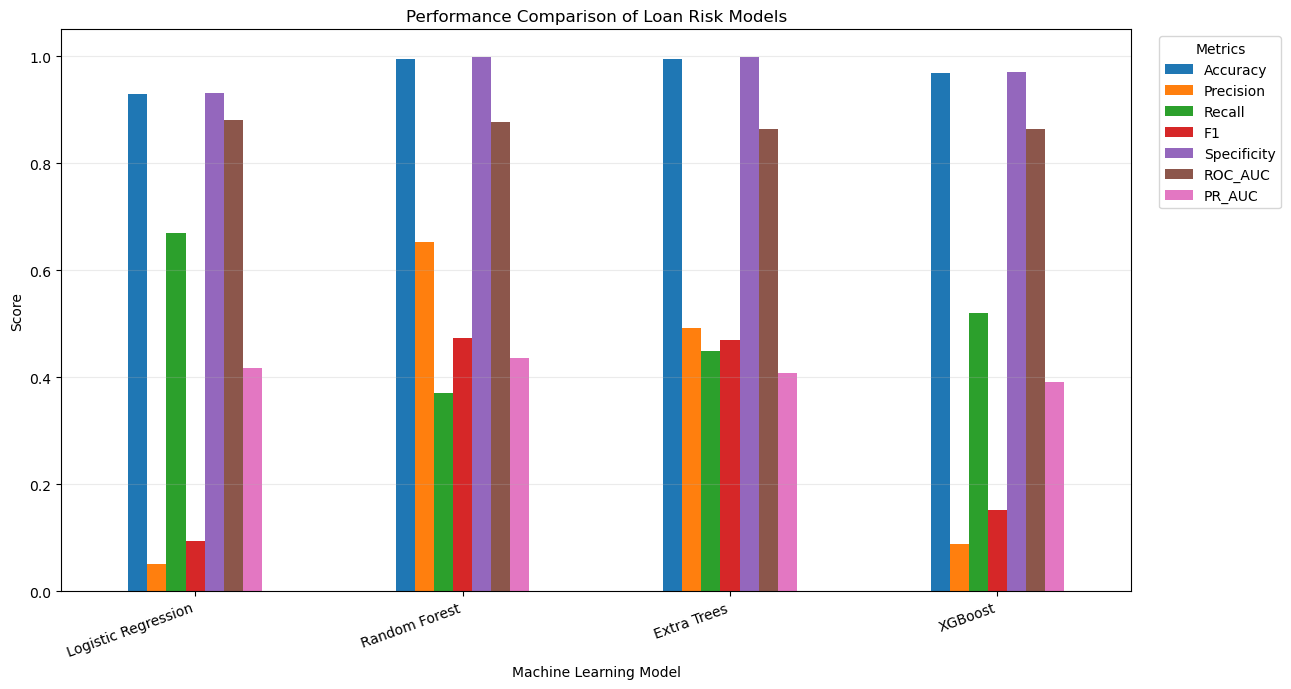


Displaying Graph 5 - Confusion Matrices...


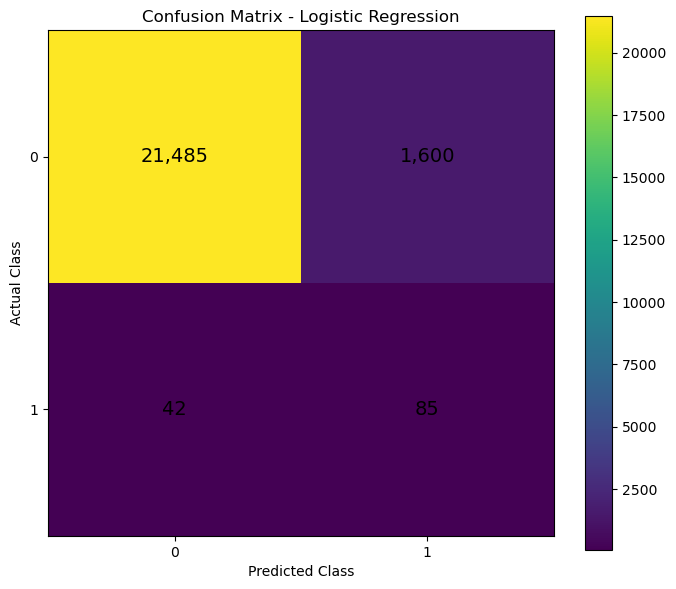

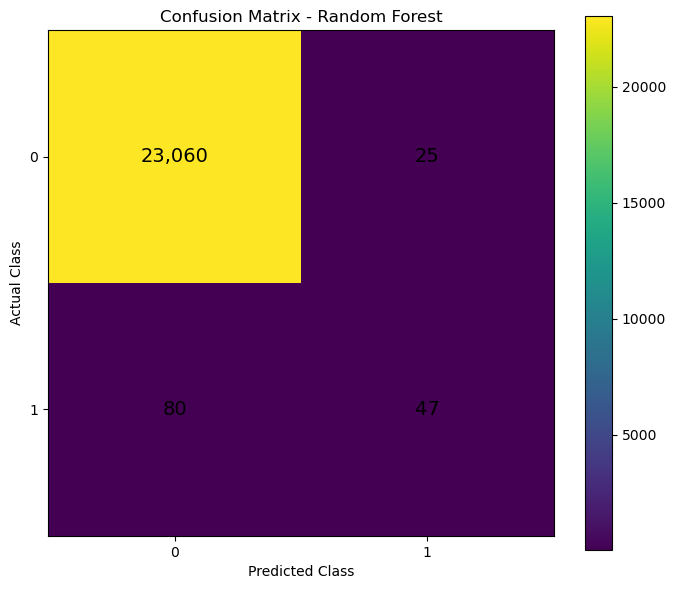

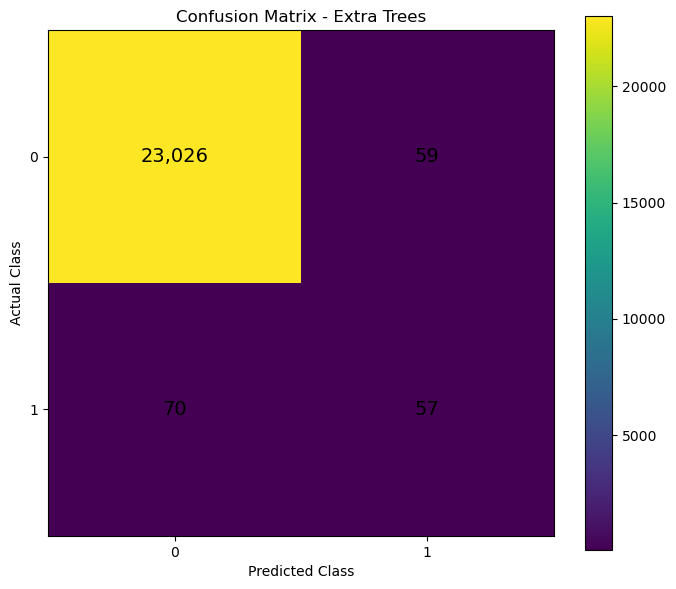

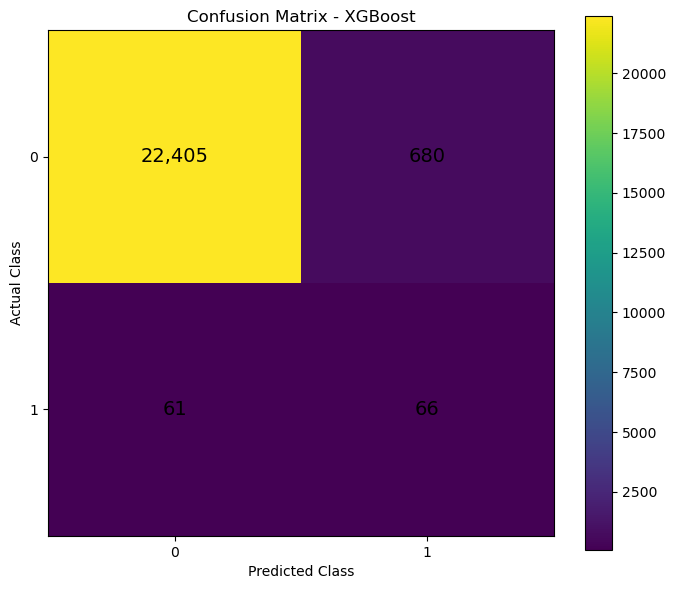


Displaying Graph 6 - Random Forest Feature Importance...


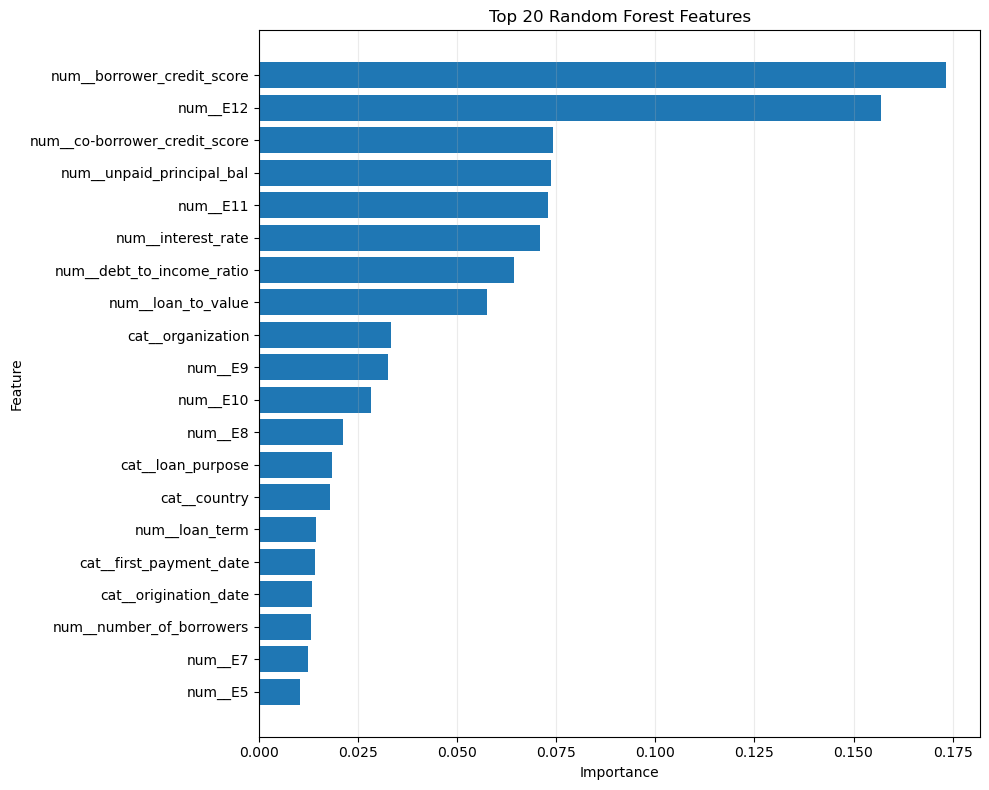


Displaying Graph 7 - Extra Trees Feature Importance...


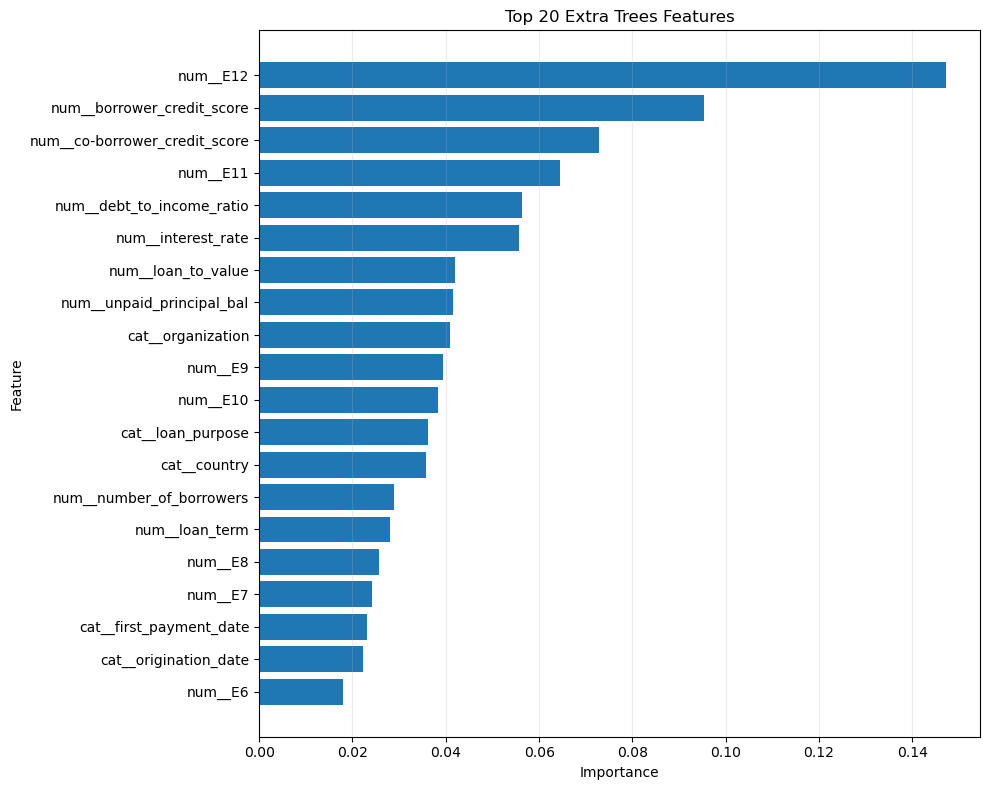


Creating confusion matrix CSV...

[10/10] Creating Excel results workbook...


                 ANALYSIS COMPLETED

Dataset processed: 116,058 rows
Target: E13

Models trained:
  ✔ Logistic Regression
  ✔ Random Forest
  ✔ Extra Trees
  ✔ XGBoost

Main graphs displayed and saved:
  ✔ Graph 1 - Target Distribution
  ✔ Graph 2 - ROC Curves
  ✔ Graph 3 - Precision-Recall Curves
  ✔ Graph 4 - Model Performance Comparison
  ✔ Graph 5 - Confusion Matrices
  ✔ Graph 6 - Random Forest Feature Importance
  ✔ Graph 7 - Extra Trees Feature Importance

Generated output folder:
C:\Users\skhee\ML_lab\loan_risk_results

Generated files:
  ✔ 01_target_distribution.png
  ✔ 02_roc_curves.png
  ✔ 03_precision_recall_curves.png
  ✔ 04_main_model_comparison.png
  ✔ 04_model_comparison_accuracy.png
  ✔ 04_model_comparison_f1.png
  ✔ 04_model_comparison_mcc.png
  ✔ 04_model_comparison_pr_auc.png
  ✔ 04_model_comparison_precision.png
  ✔ 04_model_comparison_recall.png
  ✔ 04_model_comparison_roc_auc.png
  ✔ 

In [1]:
# ============================================================
# 1. IMPORT LIBRARIES
# ============================================================
import os
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    OrdinalEncoder
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier
)
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    matthews_corrcoef,
    roc_curve,
    precision_recall_curve
)

# ============================================================
# 2. CONFIGURATION
# ============================================================
FILE = "EMI_dataset_processed.csv"
TARGET = "E13"
OUTPUT_DIR = "loan_risk_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============================================================
# 3. PROJECT HEADER
# ============================================================
print("\n" + "=" * 80)
print("          LOAN RISK MANAGEMENT - MACHINE LEARNING")
print("=" * 80)
print("\nInput file :", FILE)
print("Target     :", TARGET)
print("Output     :", OUTPUT_DIR)
print("=" * 80)

# ============================================================
# 4. LOAD DATASET
# ============================================================
print("\n[1/10] Loading dataset...")

if not os.path.exists(FILE):
    raise FileNotFoundError(
        f"""
Dataset not found:

{FILE}

Place the dataset in the same folder as this Python file.
"""
    )

if FILE.lower().endswith((".xlsx", ".xls")):
    df = pd.read_excel(FILE)
else:
    df = pd.read_csv(FILE)

print("\nDataset loaded successfully.")
print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

# ============================================================
# 5. DATASET AUDIT
# ============================================================
print("\n[2/10] Performing dataset audit...")

original_rows = len(df)
original_columns = len(df.columns)
missing_before = int(df.isna().sum().sum())
duplicates_before = int(df.duplicated().sum())

print("Missing cells :", missing_before)
print("Duplicate rows:", duplicates_before)

# Check target
if TARGET not in df.columns:
    raise ValueError(
        f"Target column '{TARGET}' was not found."
    )

# ============================================================
# 6. REMOVE DUPLICATES
# ============================================================
df = df.drop_duplicates().copy()
print("Rows after duplicate removal:", len(df))

# ============================================================
# 7. DATASET SUMMARY
# ============================================================
print("\nCreating dataset summary...")

summary_rows = []

for column in df.columns:
    summary_rows.append({
        "Column": column,
        "Data_Type": str(df[column].dtype),
        "Unique_Values": int(df[column].nunique()),
        "Missing_Values": int(df[column].isna().sum()),
        "Missing_Percent": (
            df[column].isna().sum()
            / len(df)
            * 100
        ),
        "Sample_Values": ", ".join(
            df[column]
            .dropna()
            .astype(str)
            .unique()[:5]
        )
    })

dataset_summary = pd.DataFrame(summary_rows)

dataset_summary.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "dataset_summary.csv"
    ),
    index=False
)

print("Dataset summary saved.")

# ============================================================
# 8. TARGET DISTRIBUTION
# ============================================================
print("\n[3/10] Analysing target distribution...")

# Convert target to integer
y_full = df[TARGET].astype(int)

target_counts = (
    y_full
    .value_counts()
    .sort_index()
)

target_distribution = pd.DataFrame({
    "Class": target_counts.index,
    "Count": target_counts.values,
    "Percentage": (
        target_counts.values
        / target_counts.values.sum()
        * 100
    )
})

print("\nTarget distribution:")
print(
    target_distribution.to_string(
        index=False
    )
)

target_distribution.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "target_distribution.csv"
    ),
    index=False
)

# ============================================================
# 9. GRAPH 1 - TARGET DISTRIBUTION
# ============================================================
print("\nDisplaying Graph 1 - Target Distribution...")

plt.figure(figsize=(8, 6))

bars = plt.bar(
    target_distribution["Class"].astype(str),
    target_distribution["Count"]
)

plt.xlabel("E13 Class")
plt.ylabel("Number of Records")
plt.title("E13 Target Class Distribution")

for i, value in enumerate(
    target_distribution["Count"]
):
    plt.text(
        i,
        value,
        f"{value:,}",
        ha="center",
        va="bottom"
    )

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "01_target_distribution.png"
    ),
    dpi=220
)

# IMPORTANT:
# Display graph
plt.show()
plt.close()

# ============================================================
# 10. REMOVE IDENTIFIER COLUMNS
# ============================================================
ID_COLUMNS = [
    c
    for c in [
        "candidate_id",
        "id",
        "ID"
    ]
    if c in df.columns
]

print("\nIdentifier columns removed:")
print(ID_COLUMNS)

X = df.drop(
    columns=[
        TARGET
    ] + ID_COLUMNS
)

y = df[TARGET].astype(int)

# ============================================================
# 11. IDENTIFY CATEGORICAL / NUMERICAL COLUMNS
# ============================================================
BASE_CAT_COLS = [
    "country",
    "organization",
    "origination_date",
    "first_payment_date",
    "loan_purpose",
    "insurance_type"
]

CAT_COLS = [
    c
    for c in BASE_CAT_COLS
    if c in X.columns
]

NUM_COLS = [
    c
    for c in X.columns
    if c not in CAT_COLS
]

print("\nCategorical columns:")
print(CAT_COLS)

print("\nNumerical columns:")
print(NUM_COLS)

# ============================================================
# 12. TRAIN / TEST SPLIT
# ============================================================
print("\n[4/10] Creating stratified train/test split...")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("\nTraining records:", len(X_train))
print("Testing records :", len(X_test))

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

# ============================================================
# 13. PREPROCESSING FOR LOGISTIC REGRESSION
# ============================================================
pre_linear = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="median"
                    )
                ),
                (
                    "scaler",
                    StandardScaler()
                )
            ]),
            NUM_COLS
        ),
        (
            "cat",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="most_frequent"
                    )
                ),
                (
                    "onehot",
                    OneHotEncoder(
                        handle_unknown="ignore"
                    )
                )
            ]),
            CAT_COLS
        )
    ]
)

# ============================================================
# 14. PREPROCESSING FOR TREE MODELS
# ============================================================
pre_tree = ColumnTransformer(
    transformers=[
        (
            "num",
            SimpleImputer(
                strategy="median"
            ),
            NUM_COLS
        ),
        (
            "cat",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="most_frequent"
                    )
                ),
                (
                    "ordinal",
                    OrdinalEncoder(
                        handle_unknown="use_encoded_value",
                        unknown_value=-1
                    )
                )
            ]),
            CAT_COLS
        )
    ]
)

# ============================================================
# 15. PREPARE MODELS
# ============================================================
print("\n[5/10] Preparing machine learning models...")

models = {}

# ------------------------------------------------------------
# Logistic Regression
# ------------------------------------------------------------
models["Logistic Regression"] = Pipeline([
    (
        "prep",
        pre_linear
    ),
    (
        "model",
        LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            solver="liblinear",
            random_state=42
        )
    )
])

# ------------------------------------------------------------
# Random Forest
# ------------------------------------------------------------
models["Random Forest"] = Pipeline([
    (
        "prep",
        pre_tree
    ),
    (
        "model",
        RandomForestClassifier(
            n_estimators=150,
            class_weight="balanced_subsample",
            min_samples_leaf=2,
            max_features="sqrt",
            n_jobs=-1,
            random_state=42
        )
    )
])

# ------------------------------------------------------------
# Extra Trees
# ------------------------------------------------------------
models["Extra Trees"] = Pipeline([
    (
        "prep",
        pre_tree
    ),
    (
        "model",
        ExtraTreesClassifier(
            n_estimators=150,
            class_weight="balanced",
            min_samples_leaf=2,
            max_features="sqrt",
            n_jobs=-1,
            random_state=42
        )
    )
])

# ============================================================
# 16. OPTIONAL XGBOOST
# ============================================================
try:
    from xgboost import XGBClassifier

    positive_count = int(
        (y_train == 1).sum()
    )

    negative_count = int(
        (y_train == 0).sum()
    )

    if positive_count > 0:
        scale_pos = (
            negative_count
            / positive_count
        )
    else:
        scale_pos = 1

    models["XGBoost"] = Pipeline([
        (
            "prep",
            pre_tree
        ),
        (
            "model",
            XGBClassifier(
                n_estimators=300,
                max_depth=5,
                learning_rate=0.05,
                subsample=0.85,
                colsample_bytree=0.85,
                objective="binary:logistic",
                eval_metric="aucpr",
                scale_pos_weight=scale_pos,
                tree_method="hist",
                n_jobs=-1,
                random_state=42
            )
        )
    ])

    print("\nXGBoost available.")

except ImportError:
    print("\nXGBoost is not installed.")
    print("Continuing with three models.")

# ============================================================
# 17. MODEL EVALUATION FUNCTION
# ============================================================
def evaluate_model(
    name,
    model
):
    print("\n" + "=" * 80)
    print("TRAINING:", name)
    print("=" * 80)

    # Train
    model.fit(
        X_train,
        y_train
    )

    # Probability
    probability = (
        model
        .predict_proba(
            X_test
        )[:, 1]
    )

    # Prediction
    prediction = (
        probability >= 0.50
    ).astype(int)

    # --------------------------------------------------------
    # Confusion Matrix
    # --------------------------------------------------------
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        prediction,
        labels=[0, 1]
    ).ravel()

    # --------------------------------------------------------
    # Specificity
    # --------------------------------------------------------
    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0
    )

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------
    accuracy = accuracy_score(
        y_test,
        prediction
    )

    precision = precision_score(
        y_test,
        prediction,
        zero_division=0
    )

    recall = recall_score(
        y_test,
        prediction,
        zero_division=0
    )

    f1 = f1_score(
        y_test,
        prediction,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_test,
        probability
    )

    pr_auc = average_precision_score(
        y_test,
        probability
    )

    mcc = matthews_corrcoef(
        y_test,
        prediction
    )

    result = {
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1": f1,
        "Specificity": specificity,
        "ROC_AUC": roc_auc,
        "PR_AUC": pr_auc,
        "MCC": mcc,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }

    # --------------------------------------------------------
    # Print Metrics
    # --------------------------------------------------------
    print("\nMetrics:")

    for key, value in result.items():
        if key == "Model":
            continue

        if isinstance(
            value,
            float
        ):
            print(
                f"{key:15s}: "
                f"{value:.4f}"
            )
        else:
            print(
                f"{key:15s}: "
                f"{value}"
            )

    # --------------------------------------------------------
    # Classification Report
    # --------------------------------------------------------
    report_text = classification_report(
        y_test,
        prediction,
        digits=4,
        zero_division=0
    )

    print("\nClassification Report:")
    print(report_text)

    return (
        model,
        probability,
        prediction,
        result,
        report_text
    )

# ============================================================
# 18. TRAIN ALL MODELS
# ============================================================
print("\n[6/10] Training and evaluating models...")

all_results = []
trained_models = {}
probabilities = {}
predictions = {}
classification_reports = {}

for name, model in models.items():
    (
        trained_model,
        probability,
        prediction,
        result,
        report_text
    ) = evaluate_model(
        name,
        model
    )

    trained_models[name] = trained_model
    probabilities[name] = probability
    predictions[name] = prediction
    classification_reports[name] = report_text
    all_results.append(result)

# ============================================================
# 19. MODEL METRICS TABLE
# ============================================================
results = pd.DataFrame(
    all_results
)

results.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "model_metrics.csv"
    ),
    index=False
)

print("\n" + "=" * 80)
print("FINAL MODEL METRICS")
print("=" * 80)

print(
    results.to_string(
        index=False
    )
)

# ============================================================
# 20. CLASSIFICATION REPORT FILE
# ============================================================
with open(
    os.path.join(
        OUTPUT_DIR,
        "classification_reports.txt"
    ),
    "w",
    encoding="utf-8"
) as file:
    file.write(
        "LOAN RISK MANAGEMENT ML PROJECT\n"
    )

    file.write(
        "=" * 80 + "\n\n"
    )

    for name, report in (
        classification_reports.items()
    ):
        file.write(
            "\n" + "=" * 80 + "\n"
        )

        file.write(
            name + "\n"
        )

        file.write(
            "=" * 80 + "\n"
        )

        file.write(
            report
        )

# ============================================================
# 21. GRAPH 2 - ROC CURVES
# ============================================================
print("\n[7/10] Displaying Graph 2 - ROC Curves...")

plt.figure(figsize=(10, 7))

for name, probability in (
    probabilities.items()
):
    fpr, tpr, _ = roc_curve(
        y_test,
        probability
    )

    auc = roc_auc_score(
        y_test,
        probability
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC={auc:.3f})"
    )

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Loan Risk Models")
plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "02_roc_curves.png"
    ),
    dpi=220
)

plt.show()
plt.close()

# ============================================================
# 22. GRAPH 3 - PRECISION RECALL CURVES
# ============================================================
print("\n[8/10] Displaying Graph 3 - Precision-Recall Curves...")

plt.figure(figsize=(10, 7))

for name, probability in (
    probabilities.items()
):
    precision, recall, _ = precision_recall_curve(
        y_test,
        probability
    )

    ap = average_precision_score(
        y_test,
        probability
    )

    plt.plot(
        recall,
        precision,
        linewidth=2,
        label=f"{name} (AP={ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves - Loan Risk Models")
plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "03_precision_recall_curves.png"
    ),
    dpi=220
)

plt.show()
plt.close()

# ============================================================
# 23. GRAPH 4 - MAIN MODEL PERFORMANCE COMPARISON
# ============================================================
print("\n[9/10] Displaying Graph 4 - Model Performance Comparison...")

comparison_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "Specificity",
    "ROC_AUC",
    "PR_AUC"
]

plot_data = results.set_index(
    "Model"
)[comparison_metrics]

ax = plot_data.plot(
    kind="bar",
    figsize=(13, 7)
)

plt.title("Performance Comparison of Loan Risk Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1.05)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.legend(
    title="Metrics",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUTPUT_DIR,
        "04_main_model_comparison.png"
    ),
    dpi=220
)

plt.show()
plt.close()

# ============================================================
# 24. GRAPH 5 - CONFUSION MATRICES
# ============================================================
print("\nDisplaying Graph 5 - Confusion Matrices...")

for name in predictions:
    cm = confusion_matrix(
        y_test,
        predictions[name],
        labels=[0, 1]
    )

    plt.figure(figsize=(7, 6))

    plt.imshow(cm)

    plt.title(
        f"Confusion Matrix - {name}"
    )

    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")

    plt.xticks(
        [0, 1],
        ["0", "1"]
    )

    plt.yticks(
        [0, 1],
        ["0", "1"]
    )

    for i in range(2):
        for j in range(2):
            plt.text(
                j,
                i,
                f"{cm[i, j]:,}",
                ha="center",
                va="center",
                fontsize=14
            )

    plt.colorbar()
    plt.tight_layout()

    safe_name = (
        name
        .lower()
        .replace(
            " ",
            "_"
        )
    )

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            f"05_confusion_matrix_{safe_name}.png"
        ),
        dpi=220
    )

    plt.show()
    plt.close()

# ============================================================
# 25. RANDOM FOREST FEATURE IMPORTANCE
# ============================================================
print("\nDisplaying Graph 6 - Random Forest Feature Importance...")

rf_importance = None

if "Random Forest" in trained_models:
    rf = trained_models[
        "Random Forest"
    ]

    prep = rf.named_steps[
        "prep"
    ]

    estimator = rf.named_steps[
        "model"
    ]

    feature_names = (
        prep.get_feature_names_out()
    )

    rf_importance = pd.DataFrame({
        "Feature": feature_names,
        "Importance": estimator.feature_importances_
    })

    rf_importance = (
        rf_importance
        .sort_values(
            "Importance",
            ascending=False
        )
    )

    rf_importance.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "random_forest_feature_importance.csv"
        ),
        index=False
    )

    top_rf = rf_importance.head(20)

    plt.figure(figsize=(10, 8))

    plt.barh(
        top_rf["Feature"][::-1],
        top_rf["Importance"][::-1]
    )

    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.title("Top 20 Random Forest Features")

    plt.grid(
        axis="x",
        alpha=0.25
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "06_random_forest_feature_importance.png"
        ),
        dpi=220
    )

    plt.show()
    plt.close()

# ============================================================
# 26. EXTRA TREES FEATURE IMPORTANCE
# ============================================================
print("\nDisplaying Graph 7 - Extra Trees Feature Importance...")

et_importance = None

if "Extra Trees" in trained_models:
    et = trained_models[
        "Extra Trees"
    ]

    prep = et.named_steps[
        "prep"
    ]

    estimator = et.named_steps[
        "model"
    ]

    feature_names = (
        prep.get_feature_names_out()
    )

    et_importance = pd.DataFrame({
        "Feature": feature_names,
        "Importance": estimator.feature_importances_
    })

    et_importance = (
        et_importance
        .sort_values(
            "Importance",
            ascending=False
        )
    )

    et_importance.to_csv(
        os.path.join(
            OUTPUT_DIR,
            "extra_trees_feature_importance.csv"
        ),
        index=False
    )

    top_et = et_importance.head(20)

    plt.figure(figsize=(10, 8))

    plt.barh(
        top_et["Feature"][::-1],
        top_et["Importance"][::-1]
    )

    plt.xlabel("Importance")
    plt.ylabel("Feature")
    plt.title("Top 20 Extra Trees Features")

    plt.grid(
        axis="x",
        alpha=0.25
    )

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            OUTPUT_DIR,
            "07_extra_trees_feature_importance.png"
        ),
        dpi=220
    )

    plt.show()
    plt.close()

# ============================================================
# 27. CONFUSION MATRIX CSV
# ============================================================
print("\nCreating confusion matrix CSV...")

confusion_rows = []

for name, prediction in (
    predictions.items()
):
    tn, fp, fn, tp = confusion_matrix(
        y_test,
        prediction,
        labels=[0, 1]
    ).ravel()

    confusion_rows.append({
        "Model": name,
        "True_Negative": tn,
        "False_Positive": fp,
        "False_Negative": fn,
        "True_Positive": tp
    })

confusion_df = pd.DataFrame(
    confusion_rows
)

confusion_df.to_csv(
    os.path.join(
        OUTPUT_DIR,
        "confusion_matrices.csv"
    ),
    index=False
)

# ============================================================
# 28. EXCEL WORKBOOK
# ============================================================
print("\n[10/10] Creating Excel results workbook...")

excel_path = os.path.join(
    OUTPUT_DIR,
    "loan_risk_analysis.xlsx"
)

with pd.ExcelWriter(
    excel_path,
    engine="openpyxl"
) as writer:
    dataset_summary.to_excel(
        writer,
        sheet_name="Dataset Summary",
        index=False
    )

    target_distribution.to_excel(
        writer,
        sheet_name="Target Distribution",
        index=False
    )

    results.to_excel(
        writer,
        sheet_name="Model Metrics",
        index=False
    )

    confusion_df.to_excel(
        writer,
        sheet_name="Confusion Matrices",
        index=False
    )

    if rf_importance is not None:
        rf_importance.to_excel(
            writer,
            sheet_name="RF Feature Importance",
            index=False
        )

    if et_importance is not None:
        et_importance.to_excel(
            writer,
            sheet_name="ET Feature Importance",
            index=False
        )

# ============================================================
# 29. COMPLETE TEXT REPORT
# ============================================================
report_path = os.path.join(
    OUTPUT_DIR,
    "analysis_report.txt"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as file:
    file.write("=" * 80 + "\n")
    file.write(
        "       LOAN RISK MANAGEMENT ML PROJECT REPORT\n"
    )
    file.write("=" * 80 + "\n\n")

    # Dataset information
    file.write("DATASET INFORMATION\n")
    file.write("-" * 80 + "\n")
    file.write(f"Input file: {FILE}\n")
    file.write(f"Original rows: {original_rows}\n")
    file.write(f"Original columns: {original_columns}\n")
    file.write(
        f"Rows after duplicate removal: {len(df)}\n"
    )
    file.write(
        f"Missing cells detected: {missing_before}\n"
    )
    file.write(
        f"Duplicate rows detected: {duplicates_before}\n\n"
    )

    # Target
    file.write("TARGET INFORMATION\n")
    file.write("-" * 80 + "\n")
    file.write(f"Target column: {TARGET}\n")
    file.write(
        "E13 is treated as the binary target specified "
        "for this machine learning experiment.\n\n"
    )

    # Target distribution
    file.write("TARGET DISTRIBUTION\n")
    file.write("-" * 80 + "\n")
    file.write(
        target_distribution.to_string(
            index=False
        )
    )
    file.write("\n\n")

    # Models
    file.write("MODELS EVALUATED\n")
    file.write("-" * 80 + "\n")

    for name in models:
        file.write(
            f"- {name}\n"
        )

    file.write("\n")

    # Metrics
    file.write("MODEL METRICS\n")
    file.write("-" * 80 + "\n")
    file.write(
        results.to_string(
            index=False
        )
    )
    file.write("\n\n")

    # Classification reports
    file.write("CLASSIFICATION REPORTS\n")
    file.write("-" * 80 + "\n")

    for name, report in (
        classification_reports.items()
    ):
        file.write(
            "\n" + "=" * 70 + "\n"
        )

        file.write(name)

        file.write(
            "\n" + "=" * 70 + "\n"
        )

        file.write(report)
        file.write("\n")

# ============================================================
# 30. FINAL SUMMARY
# ============================================================
print("\n")
print("=" * 80)
print("                 ANALYSIS COMPLETED")
print("=" * 80)
print(f"\nDataset processed: {len(df):,} rows")
print(f"Target: {TARGET}")

print("\nModels trained:")

for name in trained_models:
    print("  ✔", name)

print("\nMain graphs displayed and saved:")
print("  ✔ Graph 1 - Target Distribution")
print("  ✔ Graph 2 - ROC Curves")
print("  ✔ Graph 3 - Precision-Recall Curves")
print("  ✔ Graph 4 - Model Performance Comparison")
print("  ✔ Graph 5 - Confusion Matrices")
print("  ✔ Graph 6 - Random Forest Feature Importance")
print("  ✔ Graph 7 - Extra Trees Feature Importance")

print("\nGenerated output folder:")
print(os.path.abspath(OUTPUT_DIR))

print("\nGenerated files:")

for filename in sorted(
    os.listdir(OUTPUT_DIR)
):
    print("  ✔", filename)

print("\n")
print("=" * 80)
print(
    "Use the files inside 'loan_risk_results' for your"
)
print(
    "report, PPT, graphs and ML project documentation."
)
print("=" * 80)